In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import numpy as np
import duckdb as ddb
from select import select

supply_data = pd.read_csv('data/supply_data.csv', parse_dates=['date_mpt_he'])
print(supply_data.info())
print(supply_data.isna().any(axis=1).sum())

full_range = pd.date_range(supply_data['date_mpt_he'].min(), supply_data['date_mpt_he'].max(), freq='h')
gap = full_range.difference(supply_data['date_mpt_he'])
print(gap)

<class 'pandas.DataFrame'>
RangeIndex: 6443989 entries, 0 to 6443988
Data columns (total 6 columns):
 #   Column            Dtype         
---  ------            -----         
 0   date_mpt_he       datetime64[us]
 1   asset_short_name  str           
 2   volume            float64       
 3   max_capability    float64       
 4   fuel_type         str           
 5   sub_fuel_type     str           
dtypes: datetime64[us](1), float64(2), str(3)
memory usage: 295.0 MB
None
0
DatetimeIndex(['2023-03-12 03:00:00', '2024-03-10 03:00:00',
               '2025-03-09 03:00:00', '2026-03-08 03:00:00'],
              dtype='datetime64[us]', freq=None)


#### Maximum Capability
Maximum capability for each fuel type is computed by first taking the maximum capability of each asset per day. That is then used to sum up to maximum capability for each fuel type.

In [36]:
asset_max_cap = ddb.sql(
    '''
    select
        date(date_mpt_he - interval 1 hour) as date,
        asset_short_name,
        max(max_capability) as max_cap,
        fuel_type
    from
        supply_data
    group by
        date,
        asset_short_name,
        fuel_type
    order by
        date,
        max_cap desc
    ''')
print(asset_max_cap)
s = asset_max_cap.df()
print(len(s))
print(s['max_cap'].describe())

┌────────────┬──────────────────┬─────────┬───────────┐
│    date    │ asset_short_name │ max_cap │ fuel_type │
│    date    │     varchar      │ double  │  varchar  │
├────────────┼──────────────────┼─────────┼───────────┤
│ 2023-01-01 │ EGC1             │   868.0 │ GAS       │
│ 2023-01-01 │ SCL1             │   510.0 │ GAS       │
│ 2023-01-01 │ SCR6             │   497.0 │ GAS       │
│ 2023-01-01 │ JOF1             │   474.0 │ GAS       │
│ 2023-01-01 │ GN3              │   466.0 │ DUAL FUEL │
│ 2023-01-01 │ TVS1             │   465.0 │ SOLAR     │
│ 2023-01-01 │ KH3              │   463.0 │ GAS       │
│ 2023-01-01 │ GN2              │   420.0 │ COAL      │
│ 2023-01-01 │ SD6              │   401.0 │ GAS       │
│ 2023-01-01 │ SH1              │   400.0 │ GAS       │
│     ·      │  ·               │      ·  │  ·        │
│     ·      │  ·               │      ·  │  ·        │
│     ·      │  ·               │      ·  │  ·        │
│ 2023-02-26 │ CLY1             │    41.0 │ SOLA

        date  daily_fuel_max_cap       fuel_type
0 2023-01-01             10894.0             GAS
1 2023-01-01              3618.0            WIND
2 2023-01-01              1138.0           SOLAR
3 2023-01-01               894.0           HYDRO
4 2023-01-01               820.0            COAL
5 2023-01-01               466.0       DUAL FUEL
6 2023-01-01               444.0           OTHER
7 2023-01-01                70.0  ENERGY STORAGE
8 2023-01-02             10894.0             GAS
9 2023-01-02              3618.0            WIND


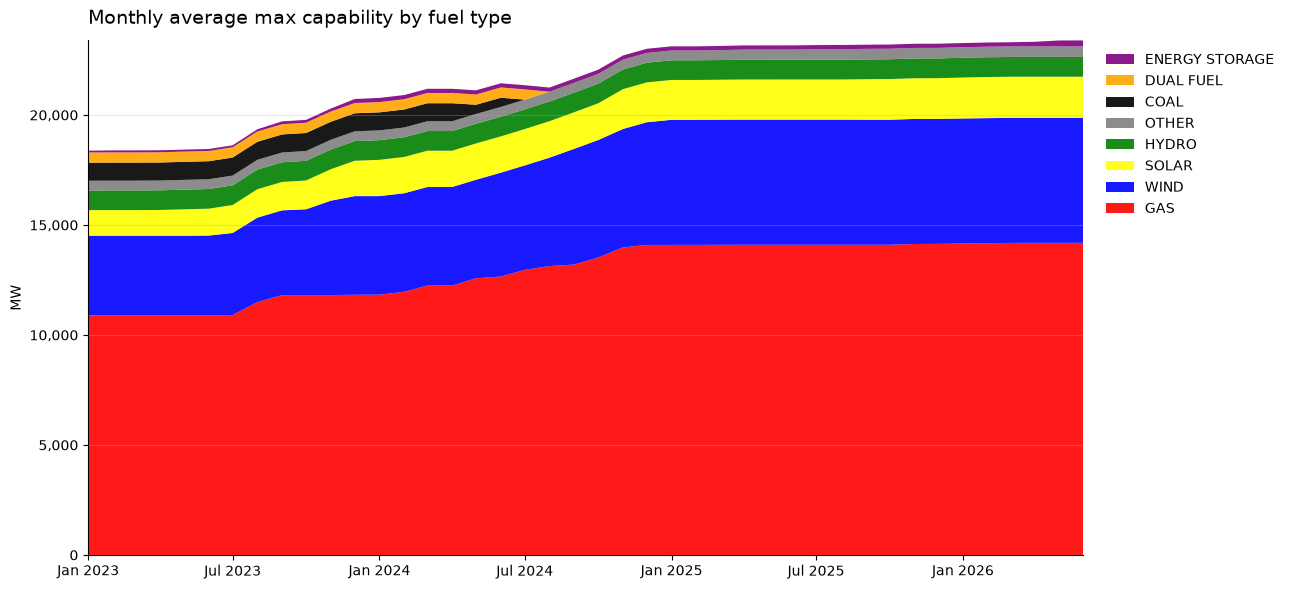

In [55]:
max_cap = ddb.sql('''
    with asset_max_cap as (
            select
                date(date_mpt_he - interval 1 hour) as date,
                asset_short_name,
                max(max_capability) as asset_max_cap,
                fuel_type
            from
                supply_data
            group by
                date,
                asset_short_name,
                fuel_type
            )
    select
        date,
        sum(asset_max_cap) as daily_fuel_max_cap,
        fuel_type
    from
        asset_max_cap
    group by
        date,
        fuel_type
    order by
        date,
        daily_fuel_max_cap desc
''').df()
print(max_cap.head(10))


########## PLOT ################
# Daily -> monthly average, one column per fuel
pivot = (
    max_cap.assign(date=pd.to_datetime(max_cap['date']))
    .pivot(index='date', columns='fuel_type', values='daily_fuel_max_cap')
    .resample('MS').mean()
    .fillna(0)
)

# Largest fuel at the bottom of the stack
pivot = pivot[pivot.mean().sort_values(ascending=False).index]

colors = {
    'GAS': 'red',
    'WIND': 'blue',
    'SOLAR': 'yellow',
    'HYDRO': 'green',
    'COAL': 'black',
    'DUAL FUEL': 'orange',
    'ENERGY STORAGE': 'purple',
    'OTHER': 'gray',
}

fig, ax = plt.subplots(figsize=(13, 6))
ax.stackplot(pivot.index, pivot.T.values,
             labels=pivot.columns,
             colors=[colors.get(c, '#cccccc') for c in pivot.columns],
             alpha=0.9)

ax.set_title('Monthly average max capability by fuel type', fontsize=14, loc='left', pad=12)
ax.set_ylabel('MW')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set_xlim(pivot.index.min(), pivot.index.max())
ax.margins(y=0)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc='upper left',
          bbox_to_anchor=(1.01, 1), frameon=False)

plt.tight_layout()
plt.show()

Alberta's maximum capability grew from about 18,500 MW in January 2023 to about 23,500 MW by late 2024, an increase of roughly about 27\% as new generators came online. Coal's exit in mid 2024 did not slow this growth as they were converted to gas rather than retired, so their capacity moved into the gas category.

Gas generators makes up the largest share of capability of about 14,200 MW or roughly 60\% of the fleet with wind second at about 5,700 MW.

#### Monthly Average Fuel Mix

┌─────────┬────────────────┬──────────────────┬──────────────┐
│  month  │   fuel_type    │ avg_daily_volume │ pct_of_total │
│ varchar │    varchar     │      double      │    double    │
├─────────┼────────────────┼──────────────────┼──────────────┤
│ 2023-01 │ GAS            │        183943.11 │        72.12 │
│ 2023-01 │ WIND           │         28820.42 │         11.3 │
│ 2023-01 │ COAL           │         18967.41 │         7.44 │
│ 2023-01 │ DUAL FUEL      │         11149.29 │         4.37 │
│ 2023-01 │ OTHER          │          6562.84 │         2.57 │
│ 2023-01 │ HYDRO          │          3476.77 │         1.36 │
│ 2023-01 │ SOLAR          │          2115.03 │         0.83 │
│ 2023-01 │ ENERGY STORAGE │            10.41 │          0.0 │
│ 2023-02 │ GAS            │        174855.11 │        69.91 │
│ 2023-02 │ WIND           │         32795.49 │        13.11 │
│    ·    │  ·             │             ·    │           ·  │
│    ·    │  ·             │             ·    │        

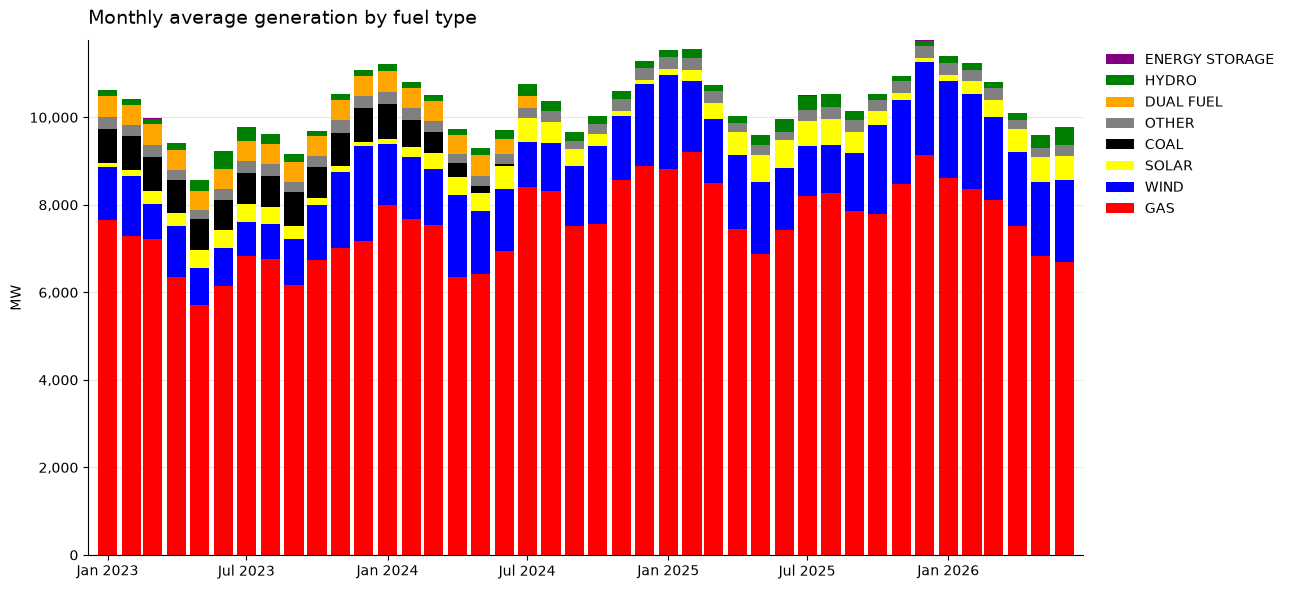

In [69]:
fuel_mix = ddb.sql('''
    with daily_fuel_mix as (
        select
            date(date_mpt_he - interval 1 hour) as date,
            fuel_type,
            sum(volume) as daily_total_volume
        from
            supply_data
        group by
            date,
            fuel_type
    )
    select
        strftime(date_trunc('month', date), '%Y-%m') as month,
        fuel_type,
        round(avg(daily_total_volume), 2) as avg_daily_volume,
        -- this fuel's total / all fuels' total for the same month
        round(100 * sum(daily_total_volume)/sum(sum(daily_total_volume)) over (partition by month), 2) as pct_of_total
    from
        daily_fuel_mix
    group by
        month,
        fuel_type
    order by
        month,
        avg_daily_volume desc
 ''')
print(fuel_mix)

# One row per month, one column per fuel.
# avg_daily_volume is MWh per day, so divide by 24 for average MW.
pivot = (
    fuel_mix.df()
    .assign(month=lambda d: pd.to_datetime(d['month']),
            avg_mw=lambda d: d['avg_daily_volume'] / 24)
    .pivot(index='month', columns='fuel_type', values='avg_mw')
    .fillna(0)
)

pivot = pivot[pivot.mean().sort_values(ascending=False).index]


fig, ax = plt.subplots(figsize=(13, 6))
bottom = np.zeros(len(pivot))
for fuel in pivot.columns:
    ax.bar(pivot.index, pivot[fuel], bottom=bottom, width=25,
           color=colors.get(fuel, '#cccccc'), label=fuel)
    bottom += pivot[fuel].values

ax.set_title('Monthly average generation by fuel type', fontsize=14, loc='left', pad=12)
ax.set_ylabel('MW')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.margins(x=0.01, y=0)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc='upper left',
          bbox_to_anchor=(1.01, 1), frameon=False)

plt.tight_layout()
plt.show()

Supply follows the same pattern as demand; this is expected because supply and demand must balance, and since demand is seasonally structured, supply must follow suit.

#### Renewables Capacity Factor

┌─────────┬───────────┬──────────────┬──────────────────────┬─────────────────────┐
│  month  │ fuel_type │ total_volume │ total_max_capability │ capacity_factor_pct │
│ varchar │  varchar  │    double    │        double        │       double        │
├─────────┼───────────┼──────────────┼──────────────────────┼─────────────────────┤
│ 2023-01 │ HYDRO     │    107779.72 │             665136.0 │                16.2 │
│ 2023-01 │ SOLAR     │     65565.93 │             864168.0 │                7.59 │
│ 2023-01 │ WIND      │    893432.94 │            2691792.0 │               33.19 │
│ 2023-02 │ HYDRO     │     88828.16 │             600768.0 │               14.79 │
│ 2023-02 │ SOLAR     │     95290.14 │             782880.0 │               12.17 │
│ 2023-02 │ WIND      │    918273.83 │            2431296.0 │               37.77 │
│ 2023-03 │ HYDRO     │     98556.72 │             664242.0 │               14.84 │
│ 2023-03 │ SOLAR     │    224579.76 │             865595.0 │               

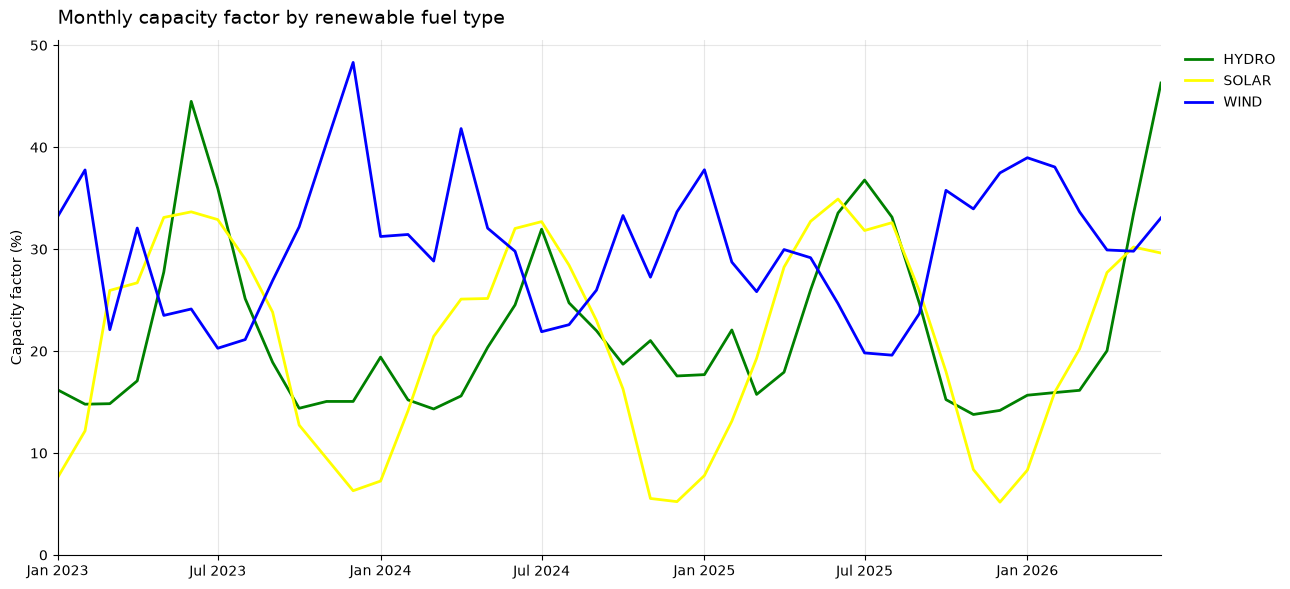

In [68]:
ren_cap_factor = ddb.sql('''
    with renewable_hourly as (
        select
            date_mpt_he - interval 1 hour as hour_beginning,
            fuel_type,
            volume,
            max_capability
        from
            supply_data
        where
            fuel_type in ('WIND', 'SOLAR', 'HYDRO')
    )
    select
        strftime(date_trunc('month', hour_beginning), '%Y-%m') as month,
        fuel_type,
        round(sum(volume), 2) as total_volume,
        sum(max_capability) as total_max_capability,
        round(sum(volume) / sum(max_capability) * 100, 2) as capacity_factor_pct
    from
        renewable_hourly
    group by
        month,
        fuel_type
    order by
        month,
        fuel_type
''')
print(ren_cap_factor)
print(ren_cap_factor.describe())

# One row per month, one column per fuel
cf = (
    ren_cap_factor.df()
    .assign(month=lambda d: pd.to_datetime(d['month']))
    .pivot(index='month', columns='fuel_type', values='capacity_factor_pct')
)

fig, ax = plt.subplots(figsize=(13, 6))
for fuel in cf.columns:
    ax.plot(cf.index, cf[fuel], color=colors[fuel], linewidth=2, label=fuel)

ax.set_title('Monthly capacity factor by renewable fuel type', fontsize=14, loc='left', pad=12)
ax.set_ylabel('Capacity factor (%)')
ax.set_ylim(0, None)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set_xlim(cf.index.min(), cf.index.max())
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)

plt.tight_layout()
plt.show()

Wind and solar run on opposite seasonal cycles with wind being more active in fall and winter, and solar in June and July. Hydro peaks in early summer with snowmelt resulting in stronger river flows.